# 02 - Dataset generation

ImageNet-OOC1k is built from two ingredients: **background-only images**, from which the original object was removed by inpainting, and **object cut-outs** from the ImageNet-S object library, each with its segmentation mask.

For our experiments, we combine the two into **composites**: we place object cut-outs onto a variety of backgrounds, so the same object appears both in scenes that are semantically close to it and in scenes that are far away from it.

This notebook generates these composites. We first set the paths, then the generation parameters, and finally run the generation and look at a few of the resulting images. At the end, we also generate the object-only images, where each object is shown on a neutral background.

In [1]:
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd() 
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"

# ImageNet-OOC1k dataset: provided images and metadata in source/, everything we generate in generated/
DATASET_DIR = REPO_ROOT / "ImageNet-OOC1k"
SOURCE_DIR = DATASET_DIR / "source"
GENERATED_DIR = DATASET_DIR / "generated"

# Semantic axis from notebook 01 and the ImageNet class index
SIMILARITY_MATRIX = DATA_DIR / "semantic_axes" / "consensus.npy"
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"

# Where the new composites and object-only images are written
COMPOSITES_DIR = GENERATED_DIR / "composites"
OBJECT_ONLY_DIR = GENERATED_DIR / "object_only"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Generation and plotting functions live outside the notebook to keep it readable.
from ooc1k.dataset_generation.composites import generate_composites
from ooc1k.dataset_generation.object_only import generate_object_only_images
from ooc1k.plotting.b_composites import plot_composite_examples

/Users/domenicbersch/anaconda3/envs/ooc1k/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Generation parameters

The parameters below are the ones we used to create the composites in the paper. Feel free to change them if you want to generate your own set.

For every sampled background, we rank all object classes by their consensus dissimilarity to the background class, so rank 1 is the background's own class and higher ranks are semantically more distant. For each class, we sample a few object instances, scale them relative to the background, slightly jitter their brightness and colour, sometimes rotate them, and paste them at a random position.

The generation code can be found in `ooc1k/dataset_generation/composites.py`. It works well for our setup, but if you have different ideas (for example another scaling, placement or blending), change the code there and generate the images to your liking.

Every composite gets its own seed, derived from the background, the object and `SEED`, so running the generation twice with the same parameters gives identical images.

In [3]:
BG_PER_SUBCATEGORY = 10     # backgrounds per subcategory (26 subcategories -> 260 backgrounds)
OBJECTS_PER_CLASS = 4       # object instances per class and background
SCALE_MIN = 0.50            # object size relative to the background side
SCALE_MAX = 0.60
MARGIN = 0.05               # minimum distance to the image border, relative to the background side
MIN_OBJECT_DIM = 100        # minimum object side in pixels
JPEG_QUALITY = 95
SEED = 42
SAVE_MASKS = False          # also save the binary placement masks (masks.h5)
SAVE_SILHOUETTES = False    # also save the placed object cut-outs (silhouettes.h5)

## Generating the composites

All composites are stored as JPEGs in a single HDF5 file (`composites.h5`), together with a `metadata.csv` that describes each composite (background, object, dissimilarity rank and placement) and a `config.json` with the parameters above.

With the paper parameters, this gives 953,862 composites and takes about 2-3 hours on one GPU. 

In [ ]:
metadata = generate_composites(
    source_dir=SOURCE_DIR,
    similarity_matrix_path=SIMILARITY_MATRIX,
    class_index_path=CLASS_INDEX,
    output_dir=COMPOSITES_DIR,
    bg_per_subcategory=BG_PER_SUBCATEGORY,
    objects_per_class=OBJECTS_PER_CLASS,
    scale_min=SCALE_MIN,
    scale_max=SCALE_MAX,
    margin=MARGIN,
    min_object_dim=MIN_OBJECT_DIM,
    jpeg_quality=JPEG_QUALITY,
    seed=SEED,
    save_masks=SAVE_MASKS,
    save_silhouettes=SAVE_SILHOUETTES,
)

print(f"Saved to {COMPOSITES_DIR}")

Backgrounds:  48%|████▊     | 124/260 [1:17:14<1:32:07, 40.64s/it, composites=454921, skipped=35]

## A look at the composites

Here we show one composite per background at several dissimilarity ranks, from the background's own class (rank 1) to semantically distant classes.

Try changing `EXAMPLE_BACKGROUNDS` to other `background_id`s from `metadata`.

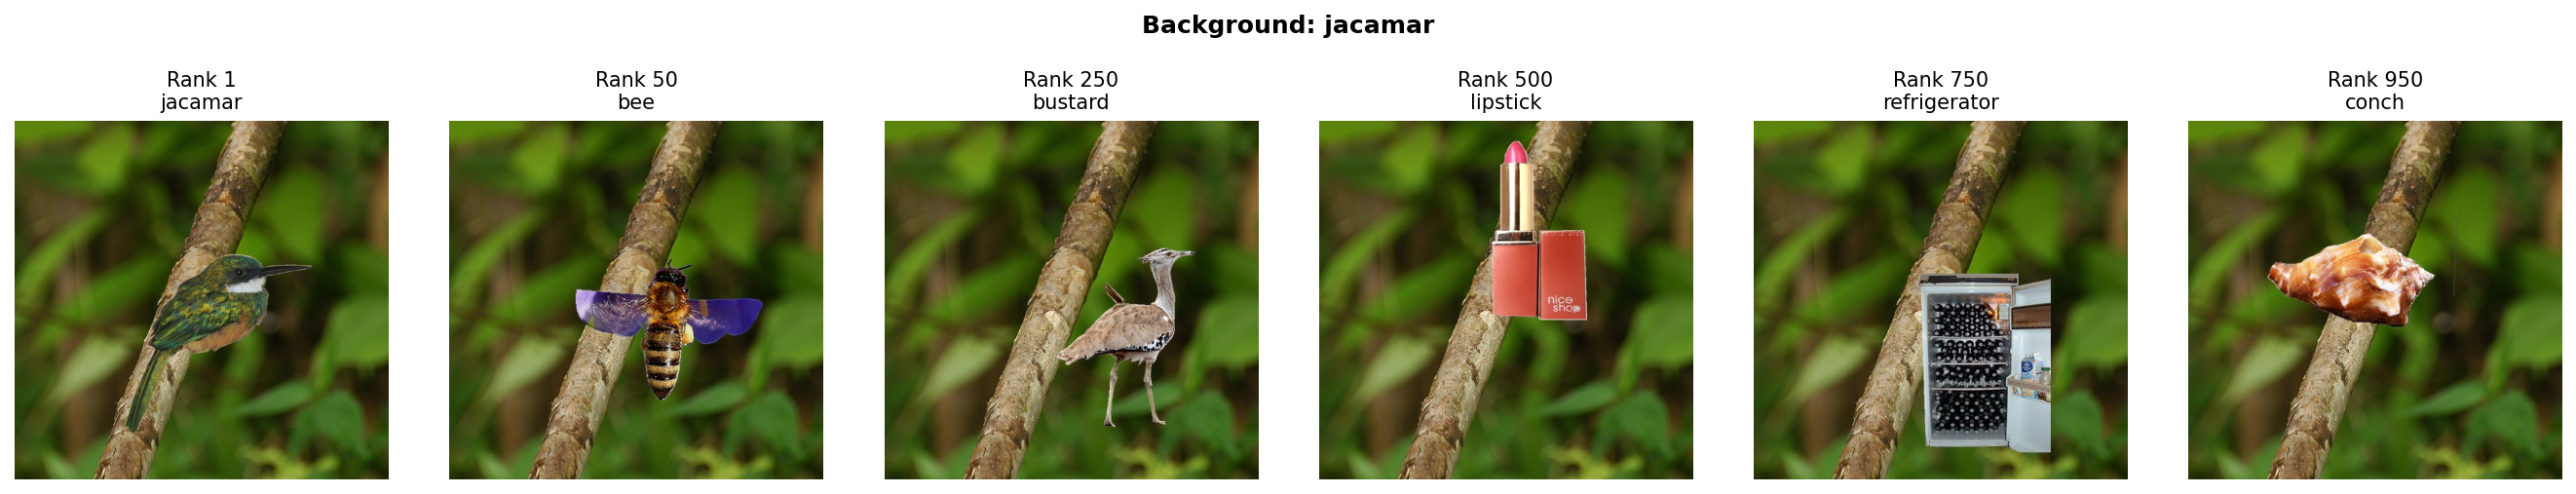

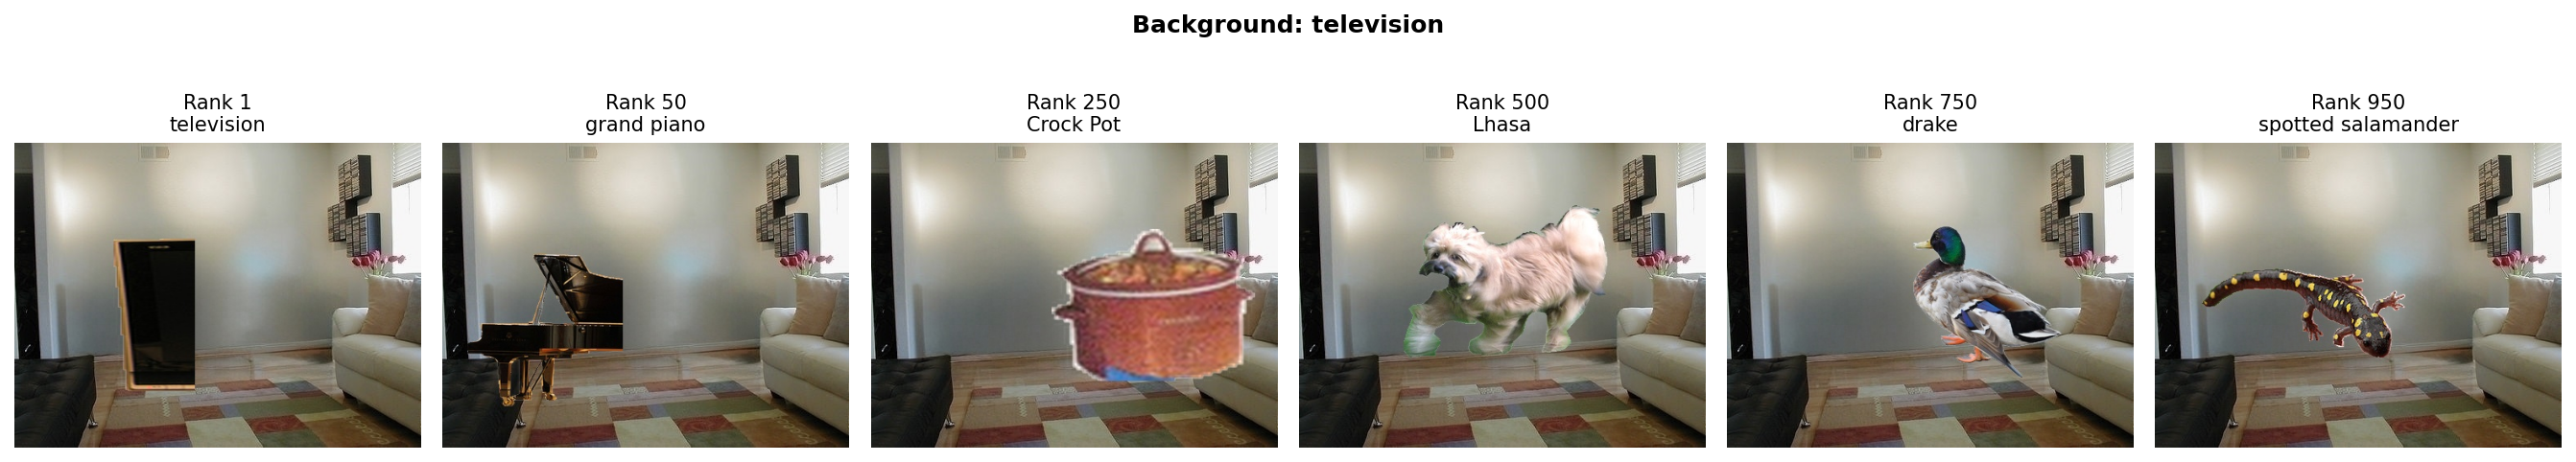

In [ ]:
EXAMPLE_BACKGROUNDS = ["ILSVRC2012_val_00008155", "ILSVRC2012_val_00042457"]  # jacamar, television
EXAMPLE_RANKS = [1, 50, 250, 500, 750, 950]

# Read the metadata from disk, so this also works without running the generation above.
metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv")

for background_id in EXAMPLE_BACKGROUNDS:
    fig = plot_composite_examples(COMPOSITES_DIR / "composites.h5", metadata, background_id, EXAMPLE_RANKS)
    plt.show()

## Object-only images

As part of the paper, we want to understand how well models recognise the objects not only in the composites, but also on their own. Together with the background-only images, this tells us how much the object and the background each contribute to recognition.

For that, we generate three versions of every object: on a black, a white and a pink-noise background. Pink noise has a 1/f spectrum like natural images, but carries no meaning. Comparing the three versions shows whether the accuracy on the object alone depends on the background it is shown on. Every object gets its own noise pattern, seeded by its file name, so running the generation twice gives identical images.

We do this for the main images and for the object library. The code can be found in `ooc1k/dataset_generation/object_only.py`. It takes a few minutes.

In [ ]:
OBJECT_ONLY_BACKGROUNDS = ("black", "white", "pink_noise")
MASK_THRESHOLD = 127        # mask values above this belong to the object

generate_object_only_images(
    source_dir=SOURCE_DIR,
    output_dir=OBJECT_ONLY_DIR,
    backgrounds=OBJECT_ONLY_BACKGROUNDS,
    mask_threshold=MASK_THRESHOLD,
)

print(f"Saved to {OBJECT_ONLY_DIR}")

Object-only (main):   0%|          | 1/1137 [00:00<02:03,  9.22it/s]

Object-only (main): 100%|██████████| 1137/1137 [01:38<00:00, 11.58it/s]


main: 1,137 objects on 3 backgrounds (0 masks without image)


Object-only (library): 100%|██████████| 12358/12358 [25:47<00:00,  7.99it/s] 

library: 12,358 objects on 3 backgrounds (0 masks without image)
Created 40,485 object-only images in 27.4 min
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/ImageNet-OOC1k/generated/object_only


## A look at the object-only images

Here we show two objects next to their original image and their background-only version.

Try changing `EXAMPLE_INDICES` to other rows of `SOURCE_DIR / "metadata_backgrounds.csv"` (0 to 1,136).


In [ ]:
from PIL import Image

EXAMPLE_INDICES = [85, 777]  # jacamar, television

# Each column shows the same image from a different folder.
VIEWS = {
    "Original": SOURCE_DIR / "originals",
    "Background only": SOURCE_DIR / "backgrounds",
    "Black": OBJECT_ONLY_DIR / "main" / "black",
    "White": OBJECT_ONLY_DIR / "main" / "white",
    "Pink noise": OBJECT_ONLY_DIR / "main" / "pink_noise",
}

image_metadata = pd.read_csv(SOURCE_DIR / "metadata_backgrounds.csv")
examples = image_metadata.iloc[EXAMPLE_INDICES]

fig, axes = plt.subplots(len(examples), len(VIEWS), figsize=(3 * len(VIEWS), 3 * len(examples)), squeeze=False)
for row, (_, example) in zip(axes, examples.iterrows()):
    for ax, (title, folder) in zip(row, VIEWS.items()):
        image_path = next(folder.rglob(f"{example['image_id']}.*"))
        ax.imshow(Image.open(image_path).convert("RGB"))
        ax.set_title(title)
        ax.axis("off")
    row[0].set_title(f"Original: {example['class_label'].replace('_', ' ')}")
fig.tight_layout()
plt.show()

## A subset for the mechanistic analysis

In notebooks 06 and 07, we look inside Vision Transformers: for every image, we extract what each patch represents in every layer. Doing this for all ~955,000 composites would take far too long and too much storage, so we draw a subset instead.

The subset should cover the whole semantic axis and all kinds of scenes equally. We therefore split the dissimilarity ranks into `SUBSET_BINS` equal-width bins and draw `SUBSET_PER_CELL` composites from every combination of bin and background category (nature, human-related, misc). With the paper settings, this gives 20 × 3 × 1,250 = 75,000 composites. We do not balance correct and incorrect predictions, so every bin keeps the error rate the models naturally have there.

The subset only depends on the composite metadata and `SEED`, so it takes a second and gives the same composites every time.

In [ ]:
SUBSET_BINS = 20            # equal-width bins over the dissimilarity ranks
SUBSET_PER_CELL = 1250      # composites per bin and background category
SUBSET_PATH = GENERATED_DIR / "mechanism_subset.csv"

composite_metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv")

# Assign every composite to one of the rank bins.
ranks = composite_metadata["dissimilarity_rank"]
bin_edges = np.linspace(ranks.min(), ranks.max() + 1, SUBSET_BINS + 1)
composite_metadata["dissimilarity_bin"] = np.digitize(ranks, bin_edges[1:-1])

# Draw the same number of composites from every combination of bin and background category.
cells = composite_metadata.groupby(["dissimilarity_bin", "background_category"])
subset = pd.concat([cell.sample(n=min(SUBSET_PER_CELL, len(cell)), random_state=SEED) for _, cell in cells])

# The row index is the position of the composite in composites.h5.
subset.to_csv(SUBSET_PATH, index_label="h5_index")
print(f"{len(subset):,} composites from {subset['background_id'].nunique()} backgrounds and {subset['object_image_name'].nunique():,} object images")
print(f"Saved to {SUBSET_PATH}")

subset.groupby(["dissimilarity_bin", "background_category"]).size().unstack()

75,000 composites from 260 backgrounds and 12,280 object images
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/ImageNet-OOC1k/generated/mechanism_subset.csv


background_category,human_related,misc,nature
dissimilarity_bin,,,
0,1250,1250,1250
1,1250,1250,1250
2,1250,1250,1250
3,1250,1250,1250
4,1250,1250,1250
5,1250,1250,1250
6,1250,1250,1250
7,1250,1250,1250
8,1250,1250,1250


## Dataset summary

Finally, let's put all the numbers of the dataset in one table.

The possible pairings are all combinations of the 1,137 backgrounds with all object images. We only use a stratified part of them, but anyone who wants more composites can generate them with the code above.

In [ ]:
background_metadata = pd.read_csv(SOURCE_DIR / "metadata_backgrounds.csv")
object_metadata = pd.read_csv(SOURCE_DIR / "metadata_objects.csv")
composite_metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv")
subset = pd.read_csv(SUBSET_PATH)

# Backgrounds per subcategory, largest first, with a total per category. Misc has no subcategories.
rows = []
for category in ["nature", "human_related", "misc"]:
    backgrounds = background_metadata[background_metadata["background_category"] == category]
    name = category.replace("_", "-").capitalize()
    for subcategory, count in backgrounds["background_subcategory"].value_counts().items():
        rows.append(("Backgrounds", f"{name}: {subcategory}", count))
    rows.append(("Backgrounds", f"{name}: total", len(backgrounds)))
rows += [
    ("Backgrounds", "Total", len(background_metadata)),
    ("Object library", "Object image-mask pairs", len(object_metadata)),
    ("Object library", "ImageNet classes", object_metadata["class_hash"].nunique()),
    ("Composites", "Generated composites", len(composite_metadata)),
    ("Composites", f"Backgrounds used ({BG_PER_SUBCATEGORY} per subcategory)", composite_metadata["background_id"].nunique()),
    ("Composites", "Possible pairings (all backgrounds x all objects)", len(background_metadata) * len(object_metadata)),
    ("Mechanism subset", f"Composites ({SUBSET_BINS} bins x 3 categories x {SUBSET_PER_CELL:,})", len(subset)),
]

summary = pd.DataFrame(rows, columns=["Component", "Detail", "Count"]).set_index(["Component", "Detail"])
summary.style.format("{:,}")